# Exploring UAVSAR L1B and L2 Interferometric Products
In this tutorial we will explore [UAVSAR Level 1B interferometric](https://doi.org/10.3334/ORNLDAAC/1979) dataset. The L1B interferometric product is derived from the [L1 Single Look Complex (SLC)](https://doi.org/10.3334/ORNLDAAC/1984) dataset, collected by [Uninhabited Aerial Vehicle Synthetic Aperture Radar (UAVSAR)](https://www.earthdata.nasa.gov/data/instruments/uavsar), a polarimetric L-band synthetic aperture radar flown on the [NASA Gulfstream-III aircraft](https://www.earthdata.nasa.gov/data/platforms/air-based-platforms/g-iii) as part of [NASA Delta-X campaign](https://www.earthdata.nasa.gov/data/projects/delta-x). This tutorial is modified from a [jupyter notebook](https://github.com/ornldaac/deltax_workshop_2022/blob/main/tutorials/deltax_applications_workshop/deltax_l1b_l2_interferograms.ipynb) developed by Talib Oliver-Cabrera of NASA JPL for [Delta-X Applications Workshop](https://github.com/ornldaac/deltax_workshop_2022). 

## Radar Interferometry
Interferometric synthetic aperture radar (InSAR) is a remote sensing technique that uses the difference of phase return between the SAR acquisitions taken over a same location in different time periods. The InSAR is widely used to observe changes in the Earth's surface due to geophysical and environmental phenomena. [NASA Delta-X campaign](https://www.earthdata.nasa.gov/data/projects/delta-x) takes advantage of the rapid-repeat acquisitions from the UAVSAR to generate interferometric products to provide spatially extensive water level change measurements within areas with emergent vegetation.

## Delta-X UAVSAR Interferometric Products

During the spring (2021-03-27 to 2021-04-18) and fall (2021-09-03 to 2021-09-13) Delta-X deployments, UAVSAR flew the same flight lines over the Atchafalaya and Terrebonne Basins in southern Louisiana repeatedly, about every 30 minutes. Nearest-neighbor (NN), NN+1, and NN+2 VV-polarization interferograms were generated from the [L1 SLC stacks](https://doi.org/10.3334/ORNLDAAC/1984). Two levels of interferometric products are available:

| Dataset | DOI | Geometry |
|---|---|---|
| Delta-X: UAVSAR L1B Interferometric Products, MRD, Louisiana, 2021 | [10.3334/ORNLDAAC/1979](https://doi.org/10.3334/ORNLDAAC/1979) | Not georeferenced |
| Delta-X: UAVSAR L2 Interferometric Products, MRD, Louisiana, 2021 | [10.3334/ORNLDAAC/2057](https://doi.org/10.3334/ORNLDAAC/2057) | Georeferenced |

Each interferogram has four products, each in ENVI format (a `.dat` binary file and a `.hdr` header) inside a zip file:

| Product | Description | Units |
|---|---|---|
| `intamp` | Interferogram amplitude | - |
| `intphase` | Wrapped interferogram phase | radians |
| `coh` | Interferometric coherence | - |
| `unwphase` | Unwrapped interferogram phase | radians |

The L2 dataset also includes a quality assurance mask (`l2_qa_mask`) of areas affected by tropospheric phase delay.

Files are named `ssssss_aaaaa_YYLLDDHHMM_yyllddhhmm_vv_product.zip`, where `ssssss` is the site name (`atchaf`, `eterre`, or `wterre`), `aaaaa` is the flight line ID, `YYLLDDHHMM` and `yyllddhhmm` are the start times (UTC) of the first and second acquisitions, and `vv` is the version number. L2 file names end with `.grd.dat.zip` for the data files and `mask.grd.zip` for the mask files.

In this tutorial, we will:

1. search and download the L1B and L2 products of one interferogram
2. inspect the coherence, wrapped phase, and unwrapped phase
3. mask out pixels with low coherence
4. extract phase profiles

## Import Libraries

In [1]:
import zipfile
from os import path
import earthaccess
import numpy as np
import pandas as pd
import geopandas as gpd
import rioxarray
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

# ESRI basemap for interactive maps
xyz = "https://server.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer/tile/{z}/{y}/{x}"
attr = "ESRI"

## Authentication
We authenticate with your NASA Earthdata Login (EDL) using the `earthaccess` python library:

In [2]:
# works if the EDL login already been persisted to a netrc
try:
    auth = earthaccess.login(strategy="netrc")
except FileNotFoundError:
    # ask for EDL credentials and persist them in a .netrc file
    auth = earthaccess.login(strategy="interactive", persist=True)

## Search Granules

We search the L1B interferometric dataset by its DOI.

In [3]:
doi_l1b = '10.3334/ORNLDAAC/1979'  # UAVSAR L1B interferometric products
granules = earthaccess.search_data(doi=doi_l1b)
print(f'Granules found: {len(granules)}')

Granules found: 1972


Each granule is one product (zip file) of one interferogram. Let's create a geopandas dataframe of the granules.

In [4]:
gdf = gpd.GeoDataFrame({'file': [path.basename(g.data_links()[0]) for g in granules]},
                       geometry=gpd.GeoSeries(granules, crs=4326))

We count the files by product type. Besides the four interferometric products of each interferogram, the dataset includes geometry files (`.rdr`) for each flight line and season, with the latitude (`lat`), longitude (`lon`), height (`hgt`), and incidence angle (`inc`) of each pixel in the radar geometry. They can be used to georeference the L1B products.

In [5]:
parts = gdf.file.str.removesuffix('.zip').str.split('_')
gdf['flight_line'] = parts.str[0] + '_' + parts.str[1]
gdf['product'] = parts.str[-1]
gdf['product'].value_counts()

product
unwphase          481
intamp            481
coh               481
intphase          481
spring.hgt.rdr      6
spring.lat.rdr      6
spring.inc.rdr      6
spring.lon.rdr      6
fall.hgt.rdr        6
fall.lat.rdr        6
fall.inc.rdr        6
fall.lon.rdr        6
Name: count, dtype: int64

The interferograms cover six flight lines over the Atchafalaya and Terrebonne Basins. We count the interferograms of each flight line.

In [6]:
ifg = gdf[gdf['product'].isin(['intamp', 'intphase', 'coh', 'unwphase'])].copy()
ifg['pair'] = parts.str[2] + '_' + parts.str[3]
ifg.groupby('flight_line').agg(interferograms=('pair', 'nunique'))

,interferograms
flight_line,
atchaf_06309,76
atchaf_19809,90
eterre_08705,81
eterre_27309,78
wterre_16300,75
wterre_34202,81


Let's plot the plot boundaries by the flight_line column.

In [7]:
gdf.explore(column='flight_line', style_kwds={'fillOpacity': 0.001}, tiles=xyz, attr=attr)

## Download Granules

We use the same interferogram as the original workshop tutorial: flight line `wterre_34202`, from acquisitions on 2021-04-06 at 18:00 and 20:32 UTC. We search both the L1B and L2 products of this interferogram by file name.

In [8]:
pair = 'wterre_34202_2104061800_2104062032'
doi_l2 = '10.3334/ORNLDAAC/2057'  # UAVSAR L2 interferometric products

# search for granules matching the pattern
g_l1b = earthaccess.search_data(doi=doi_l1b,
                                       granule_name=f'*{pair}*')
g_l2 = earthaccess.search_data(doi=doi_l2,
                                      granule_name=f'*{pair}*')

# file name and size
pd.set_option('display.max_colwidth', None)
pd.DataFrame({'Dataset': ['L1B'] * len(g_l1b) + ['L2'] * len(g_l2),
              'FileName': [path.basename(g.data_links()[0]) for g in g_l1b + g_l2],
              'Size(MB)': [round(g['size']) for g in g_l1b + g_l2]})

,Dataset,FileName,Size(MB)
0,L1B,wterre_34202_2104061800_2104062032_01_unwphase.zip,124
1,L1B,wterre_34202_2104061800_2104062032_01_intphase.zip,125
2,L1B,wterre_34202_2104061800_2104062032_01_intamp.zip,123
3,L1B,wterre_34202_2104061800_2104062032_01_coh.zip,119
4,L2,wterre_34202_2104061800_2104062032_01_intamp.grd.dat.zip,143
5,L2,wterre_34202_2104061800_2104062032_02_unwphase.grd.dat.zip,145
6,L2,wterre_34202_2104061800_2104062032_01_coh.grd.dat.zip,139
7,L2,wterre_34202_2104061800_2104062032_01_intphase.grd.dat.zip,146
8,L2,wterre_34202_2104061800_2104062032_01_l2_qa_mask.grd.zip,1


Note that the L2 unwrapped phase of this interferogram is version `02`, while the other products are version `01`. We download the nine files (~1 GB) to the local directory `data`. Files that already exist are skipped.

In [9]:
files = earthaccess.download(g_l1b + g_l2, local_path='data', threads=2)

## Part 1: L1B Interferometric Products
###  Read the ENVI Files headers
Let's print the content of the interferometric coherence (`coh`) zip file.

In [10]:
print(zipfile.ZipFile(f'data/{pair}_01_coh.zip').namelist())

['wterre_34202_2104061800_2104062032_01_coh.hdr', 'wterre_34202_2104061800_2104062032_01_coh.dat']


Each zip file contains the ENVI data file and its header. 

We can print the ENVI header file to see the raster size and data type.

In [11]:
with zipfile.ZipFile(f'data/{pair}_01_coh.zip') as z:
    print(z.read(f'{pair}_01_coh.hdr').decode())

ENVI
description = {
./wterre_34202_2104061800_2104062032_01_coh.dat}
samples = 3300
lines   = 10172
bands   = 1
header offset = 0
file type = ENVI Standard
data type = 4
interleave = bsq
byte order = 0



### Read the ENVI files
GDAL can read files inside a zip archive directly with the `/vsizip/` prefix, so we don't need to unzip them. The function below opens a product with `rioxarray` and returns an `xarray.DataArray`. The no data values are masked.

In [12]:
def open_insar(zip_path):
    # opens the ENVI data file inside a zip archive as a DataArray
    dat = [n for n in zipfile.ZipFile(zip_path).namelist() if not n.endswith('.hdr')][0]
    return rioxarray.open_rasterio(f'/vsizip/{zip_path}/{dat}', masked=True).squeeze(drop=True)

### Read the rasters

The L1B products are in the radar geometry of the acquisition: rows are along the flight direction (azimuth) and columns are across it (range). They have no geographic coordinates but pixel coordinates are provides.

In [13]:
# Interferogram amplitude `intamp`
amp = open_insar(f'data/{pair}_01_intamp.zip').values
# Wrapped interferogram phase `intphase`
w_int = open_insar(f'data/{pair}_01_intphase.zip').values
# Interferometric coherence `coh`
coh = open_insar(f'data/{pair}_01_coh.zip').values
# Unwrapped interferogram phase `unwphase`
unw_int = open_insar(f'data/{pair}_01_unwphase.zip').values
# print coh shape
print(f'Dimensions (rows, columns): {coh.shape}')

Dimensions (rows, columns): (10172, 3300)


### Inspect the interferometric coherence

Coherence measures how similar the radar signal of a pixel is between the two acquisitions, from 0 (no similarity) to 1 (identical). Open water changes between acquisitions and has low coherence. Wetlands with vegetation keep a high coherence due to the double-bounce scattering between the water surface and the vegetation structure.

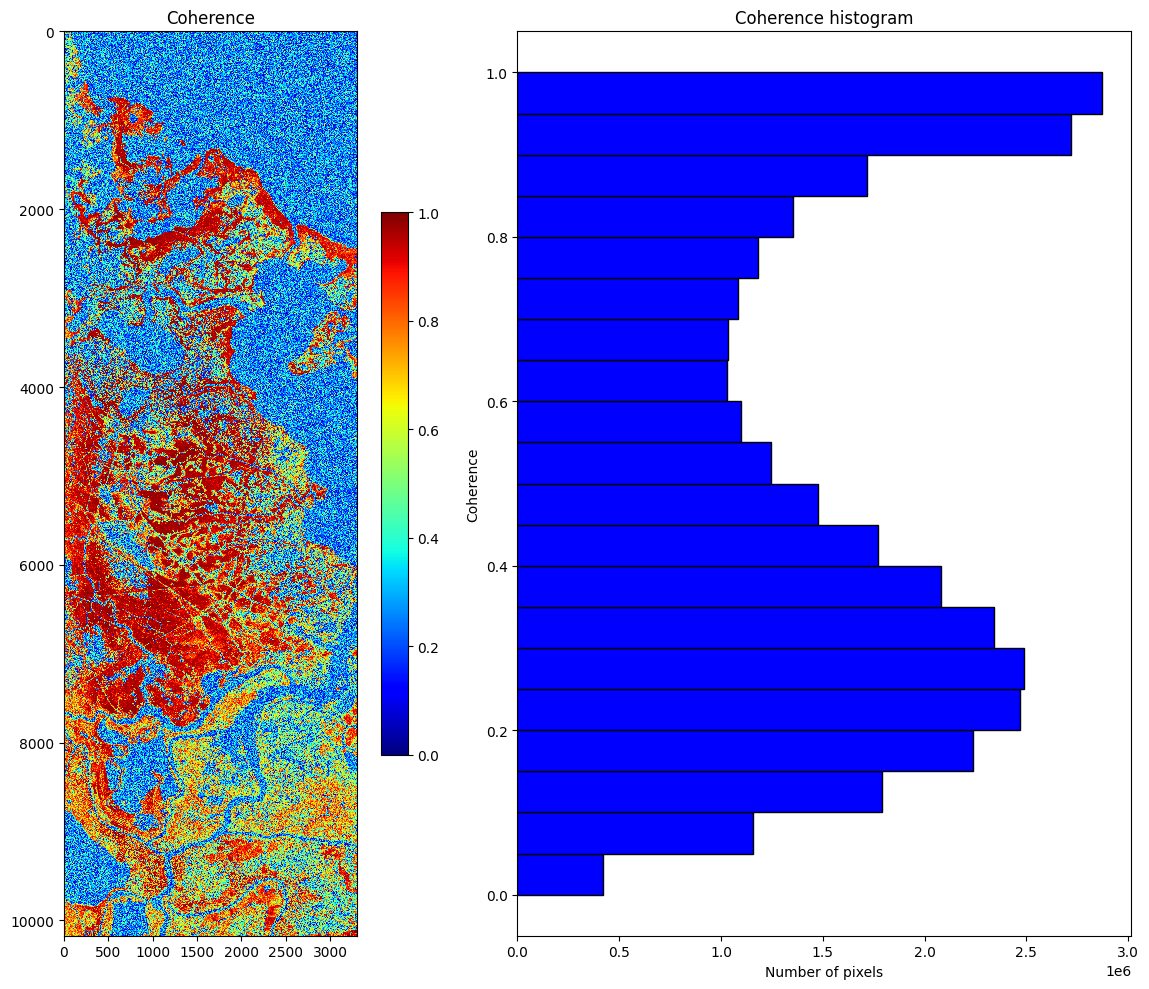

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 10),
                         gridspec_kw={'width_ratios': [1, 1.3]})
im = axes[0].imshow(coh, interpolation='nearest',
                    cmap='jet', vmin=0, vmax=1)
axes[0].set_title('Coherence')
fig.colorbar(im, ax=axes[0], shrink=0.6)
axes[1].hist(coh.ravel(), bins=20, orientation='horizontal',
             fc='b', ec='k')
axes[1].set_title('Coherence histogram')
axes[1].set_xlabel('Number of pixels')
axes[1].set_ylabel('Coherence')
plt.tight_layout()
plt.show()

### Inspect the wrapped phase

The interferometric phase (`intphase`) is the difference in phase between the two acquisitions. It wraps between -pi and pi. We plot the amplitude in decibels (dB) next to the phase for reference.

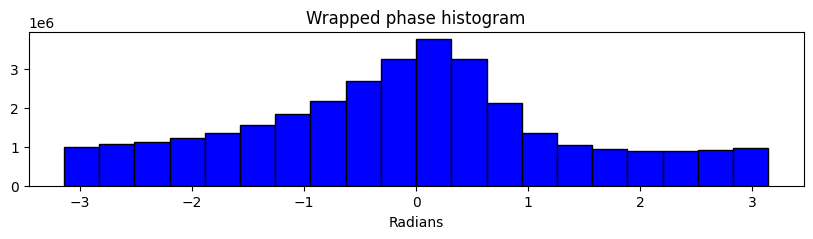

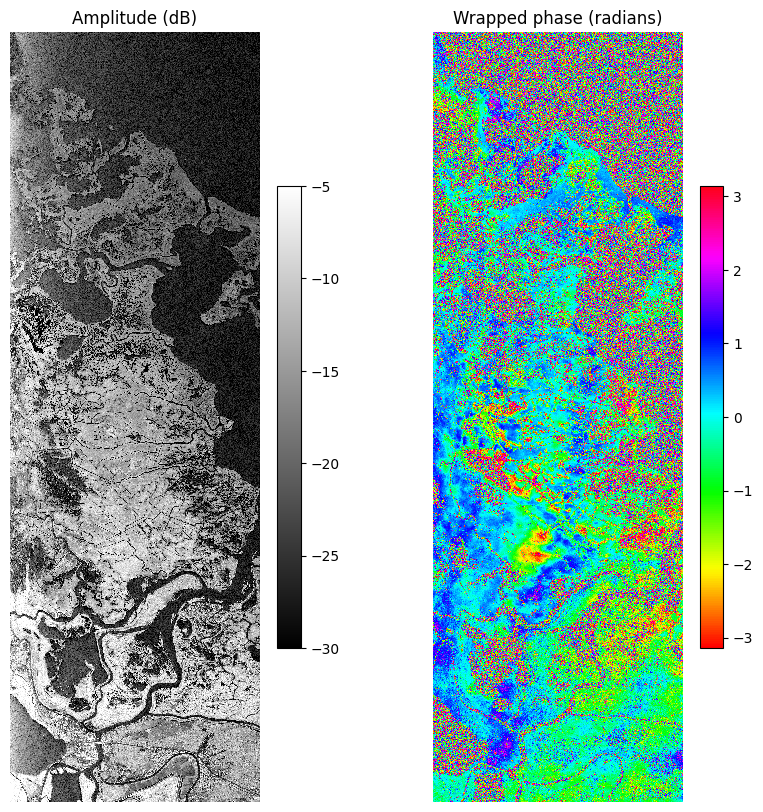

In [15]:
fig, ax = plt.subplots(figsize=(10, 2))
ax.hist(w_int.ravel(), bins=20, fc='b', ec='k')
ax.set_title('Wrapped phase histogram')
ax.set_xlabel('Radians')
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(10, 10))
im = axes[0].imshow(10 * np.log10(amp), vmin=-30, vmax=-5,
                    interpolation='nearest', cmap='gray')
axes[0].set_title('Amplitude (dB)')
fig.colorbar(im, ax=axes[0], shrink=0.6)
im = axes[1].imshow(w_int, interpolation='nearest', cmap='hsv')
axes[1].set_title('Wrapped phase (radians)')
fig.colorbar(im, ax=axes[1], shrink=0.6)
for ax in axes:
    ax.set_axis_off()
plt.show()

### Inspect the unwrapped phase

Phase unwrapping `unwphase` estimates the number of 2pi cycles in the wrapped phase, which gives a continuous phase change. The unwrapped phase is proportional to the surface change along the radar line of sight, such as a change in water level in vegetated wetlands.

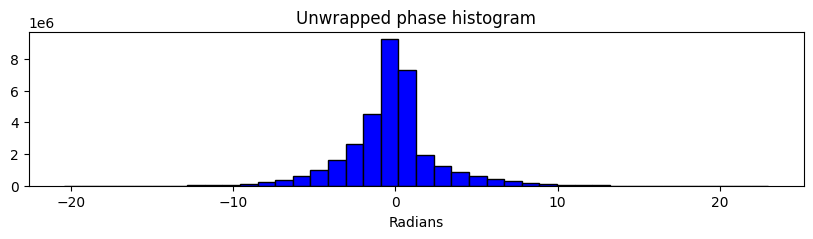

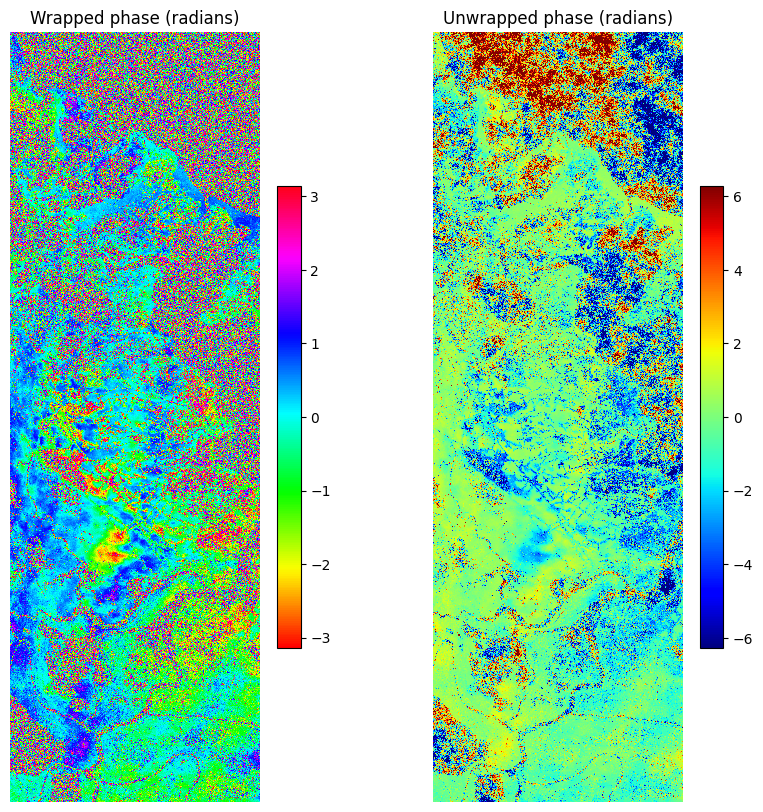

In [16]:
fig, ax = plt.subplots(figsize=(10, 2))
ax.hist(unw_int.ravel(), bins=40, fc='b', ec='k')
ax.set_title('Unwrapped phase histogram')
ax.set_xlabel('Radians')
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(10, 10))
im = axes[0].imshow(w_int, interpolation='nearest', cmap='hsv')
axes[0].set_title('Wrapped phase (radians)')
fig.colorbar(im, ax=axes[0], shrink=0.6)
im = axes[1].imshow(unw_int, vmin=-6.28, vmax=6.28,
                    interpolation='nearest', cmap='jet')
axes[1].set_title('Unwrapped phase (radians)')
fig.colorbar(im, ax=axes[1], shrink=0.6)
for ax in axes:
    ax.set_axis_off()
plt.show()

### Coherence masks

We create three masks from the coherence - pixels with high coherence (≥ 0.9), pixels with low coherence (≤ 0.3), and pixels with a coherence ≥ 0.5. The last mask keeps the coherent wetland and land pixels and removes open water and other pixels with unreliable phase. We will use it to mask the phase.

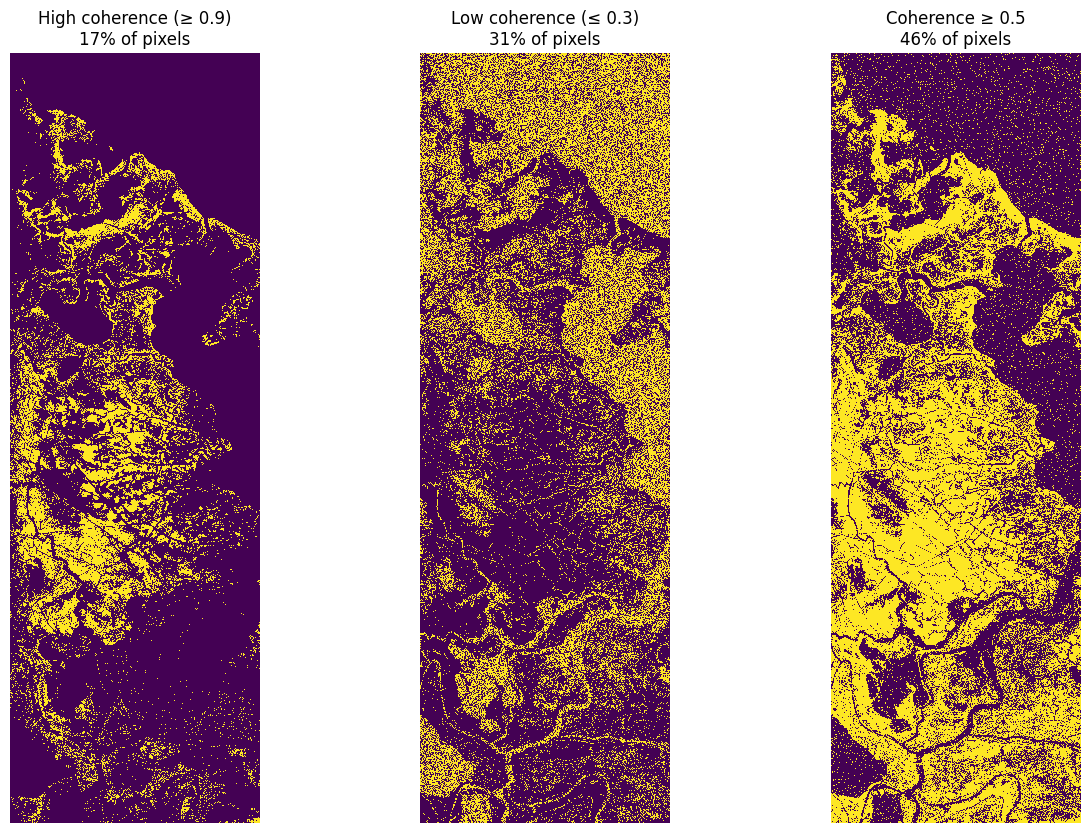

In [17]:
high_coh_msk = coh >= 0.9
low_coh_msk = coh <= 0.3
coh_msk = coh >= 0.5

fig, axes = plt.subplots(1, 3, figsize=(15, 10))
for ax, mask, title in zip(axes, 
                           [high_coh_msk, low_coh_msk, coh_msk],
                           ['High coherence (≥ 0.9)',
                            'Low coherence (≤ 0.3)',
                            'Coherence ≥ 0.5']):
    ax.imshow(mask, cmap='viridis', interpolation='nearest')
    ax.set_title(f'{title}\n{100 * mask.mean():.0f}% of pixels')
    ax.set_axis_off()
plt.show()

### Mask the phase

We set the pixels with a coherence below 0.5 to NaN in the wrapped and unwrapped phase.

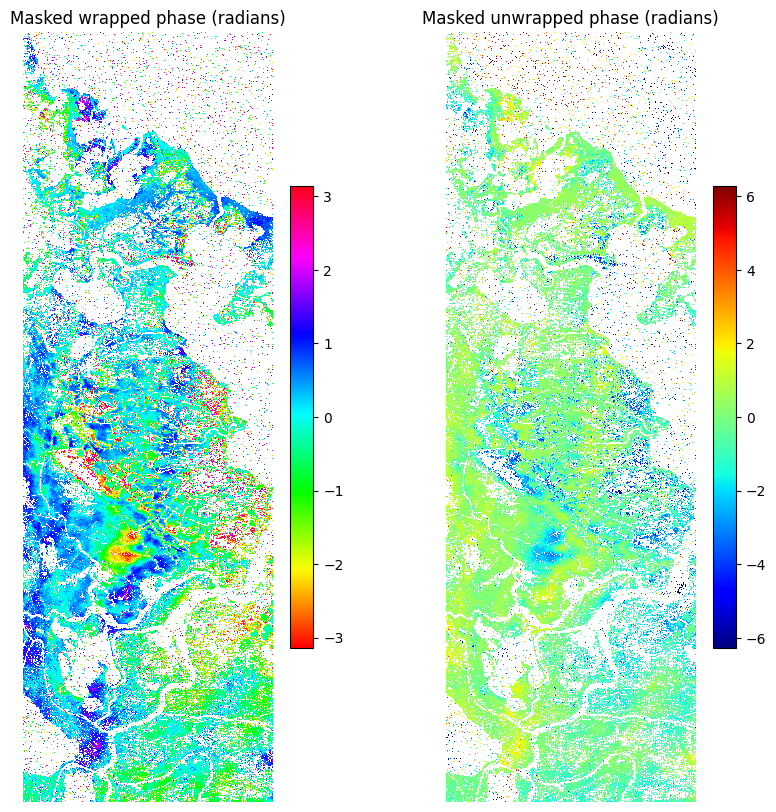

In [18]:
w_int_msk = np.where(coh_msk, w_int, np.nan)
unw_int_msk = np.where(coh_msk, unw_int, np.nan)

fig, axes = plt.subplots(1, 2, figsize=(10, 10))
im = axes[0].imshow(w_int_msk, interpolation='nearest',
                    cmap='hsv')
axes[0].set_title('Masked wrapped phase (radians)')
fig.colorbar(im, ax=axes[0], shrink=0.6)
im = axes[1].imshow(unw_int_msk, vmin=-6.28, vmax=6.28,
                    interpolation='nearest', cmap='jet')
axes[1].set_title('Masked unwrapped phase (radians)')
fig.colorbar(im, ax=axes[1], shrink=0.6)
for ax in axes:
    ax.set_axis_off()
plt.show()

### Phase profiles

We extract the masked phase along two profiles: a vertical (azimuth) profile at column 1700 from row 2000 to 4000, and a horizontal (range) profile at row 5000 from column 0 to 2500. The wrapped phase jumps between -pi and pi, while the unwrapped phase changes continuously.

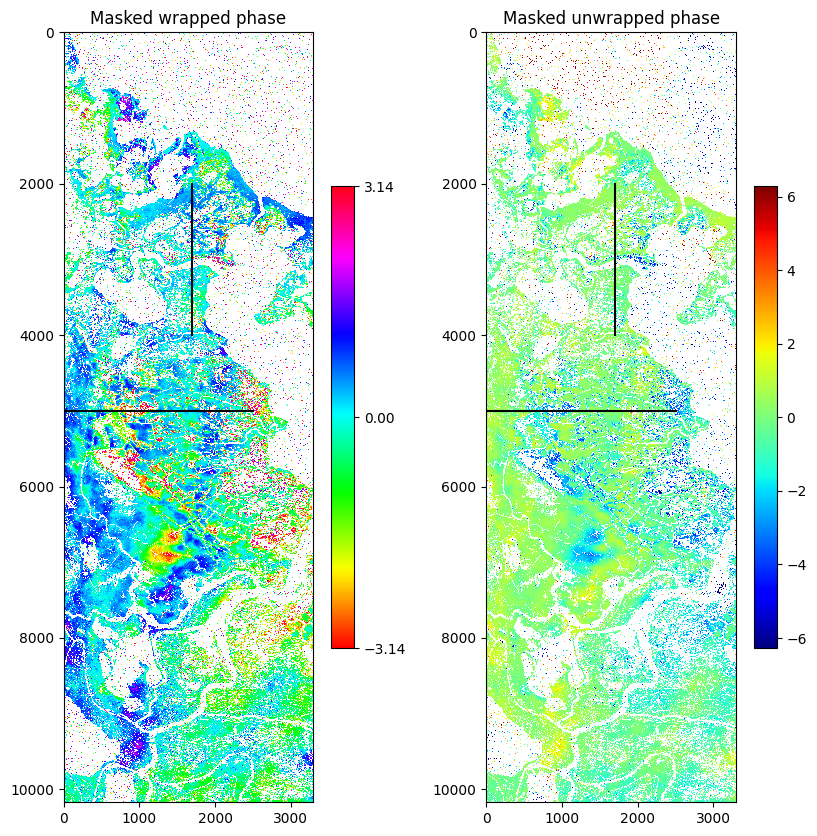

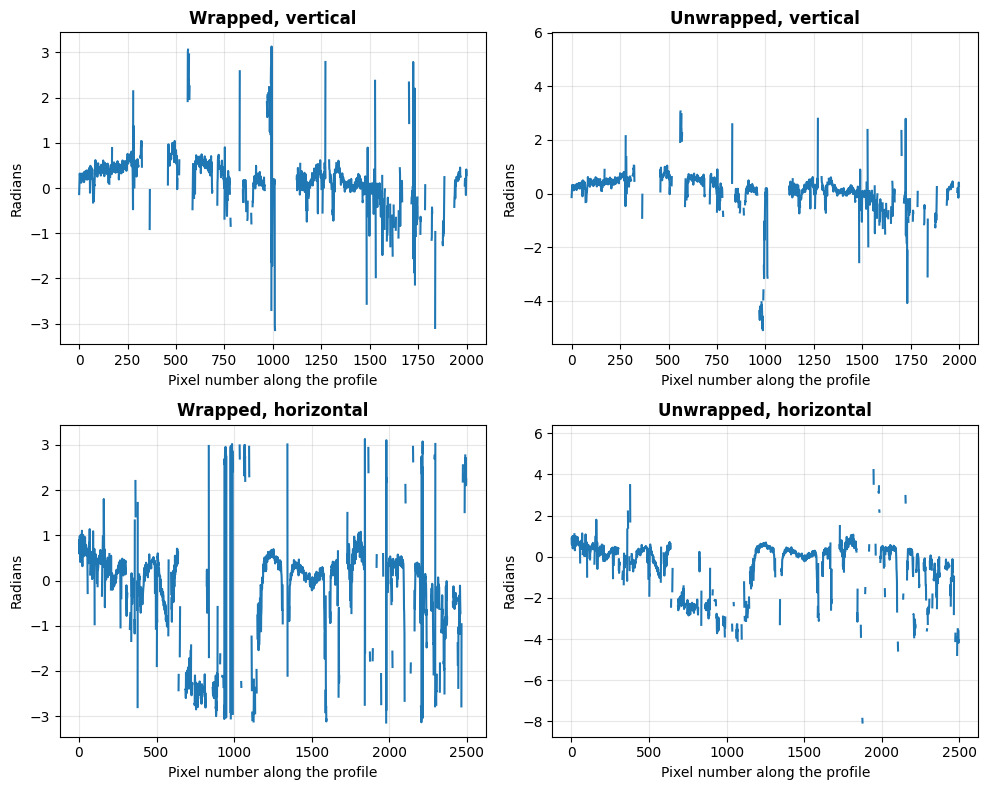

In [19]:
# vertical profile (along azimuth) and horizontal profile (along range)
v_col, v_rows = 1700, slice(2000, 4000)
h_row, h_cols = 5000, slice(0, 2500)

fig, axes = plt.subplots(1, 2, figsize=(10, 10))
im = axes[0].imshow(w_int_msk, interpolation='nearest', cmap='hsv')
axes[0].set_title('Masked wrapped phase')
fig.colorbar(im, ax=axes[0], ticks=[-3.14, 0, 3.14], shrink=0.6)
im = axes[1].imshow(unw_int_msk, vmin=-6.28, vmax=6.28,
                    interpolation='nearest', cmap='jet')
axes[1].set_title('Masked unwrapped phase')
fig.colorbar(im, ax=axes[1], shrink=0.6)
for ax in axes:
    ax.plot([v_col, v_col], [v_rows.start, v_rows.stop], '-k')
    ax.plot([h_cols.start, h_cols.stop], [h_row, h_row], '-k')
plt.show()

profiles = {
    'Wrapped, vertical': w_int_msk[v_rows, v_col],
    'Unwrapped, vertical': unw_int_msk[v_rows, v_col],
    'Wrapped, horizontal': w_int_msk[h_row, h_cols],
    'Unwrapped, horizontal': unw_int_msk[h_row, h_cols],
}
fig, axes = plt.subplots(2, 2, figsize=(10, 8))
for ax, (title, values) in zip(axes.flat, profiles.items()):
    ax.plot(values)
    ax.set_title(title, fontweight='bold')
    ax.set_xlabel('Pixel number along the profile')
    ax.set_ylabel('Radians')
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Part 2: L2 Georeferenced Interferometric Products

### Read the rasters

The L2 products are the L1B products georeferenced to a latitude/longitude grid (WGS 84). L2 rasters can be read by `rioxarray` when needed.

In [20]:
geo_amp = open_insar(f'data/{pair}_01_intamp.grd.dat.zip')
geo_w_int = open_insar(f'data/{pair}_01_intphase.grd.dat.zip')
geo_coh = open_insar(f'data/{pair}_01_coh.grd.dat.zip')
geo_unw_int = open_insar(f'data/{pair}_02_unwphase.grd.dat.zip')
geo_qa = open_insar(f'data/{pair}_01_l2_qa_mask.grd.zip')

print(f'CRS: {geo_coh.rio.crs}')
print(f'Dimensions (rows, columns): {geo_coh.shape}')
print(f'Pixel size (degrees): {geo_coh.rio.resolution()}')
print(f'Bounds (west, south, east, north): {geo_coh.rio.bounds()}')

CRS: GEOGCS["WGS 84",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0,AUTHORITY["EPSG","8901"]],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AXIS["Latitude",NORTH],AXIS["Longitude",EAST]]
Dimensions (rows, columns): (12732, 8008)
Pixel size (degrees): (5.556e-05, -5.556e-05)
Bounds (west, south, east, north): (-91.3517976749, 29.0725211089, -90.9068731949, 29.7799110289)


ERROR 1: PROJ: internal_proj_identify: /opt/homebrew/Caskroom/miniforge/base/share/proj/proj.db contains DATABASE.LAYOUT.VERSION.MINOR = 5 whereas a number >= 6 is expected. It comes from another PROJ installation.


To plot the whole scene quickly, we read every 4th pixel in each direction (`step = 4`), which is enough for an overview. We use the bounds of the raster as the plot extent.

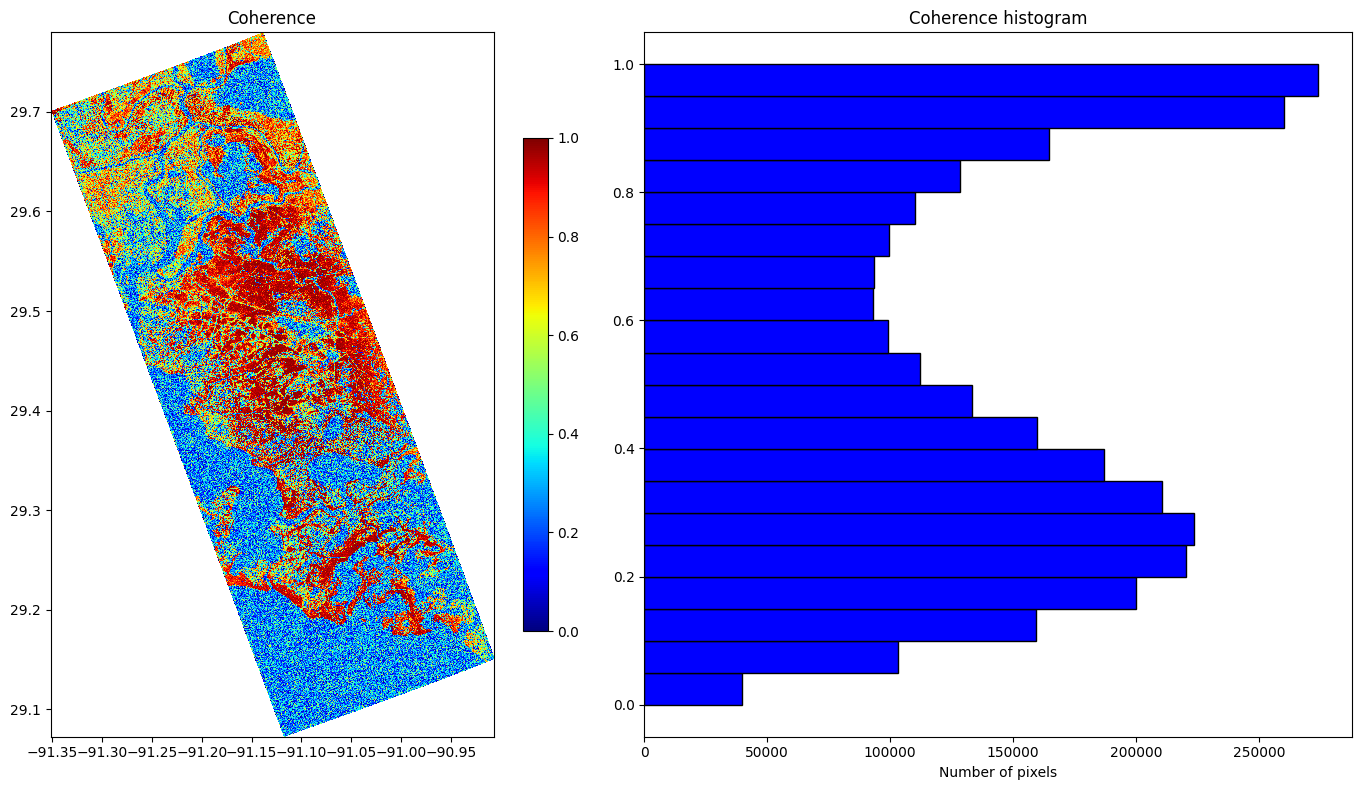

In [21]:
step = 4
# west, east, south, north
geo_extent = [geo_coh.rio.bounds()[i] for i in (0, 2, 1, 3)]

def overview(da):
    # every step-th pixel of a dataArray, as a numpy array
    return da[::step, ::step].values

coh_ov = overview(geo_coh)
fig, axes = plt.subplots(1, 2, figsize=(14, 8),
                         gridspec_kw={'width_ratios': [1, 1.2]})
im = axes[0].imshow(coh_ov, extent=geo_extent,
                    interpolation='nearest', cmap='jet',
                    vmin=0, vmax=1)
axes[0].set_title('Coherence')
fig.colorbar(im, ax=axes[0], shrink=0.7)
axes[1].hist(coh_ov[np.isfinite(coh_ov)], bins=20,
             orientation='horizontal', fc='b', ec='k')
axes[1].set_title('Coherence histogram')
axes[1].set_xlabel('Number of pixels')
plt.tight_layout()
plt.show()

### Inspect the wrapped and unwrapped phase

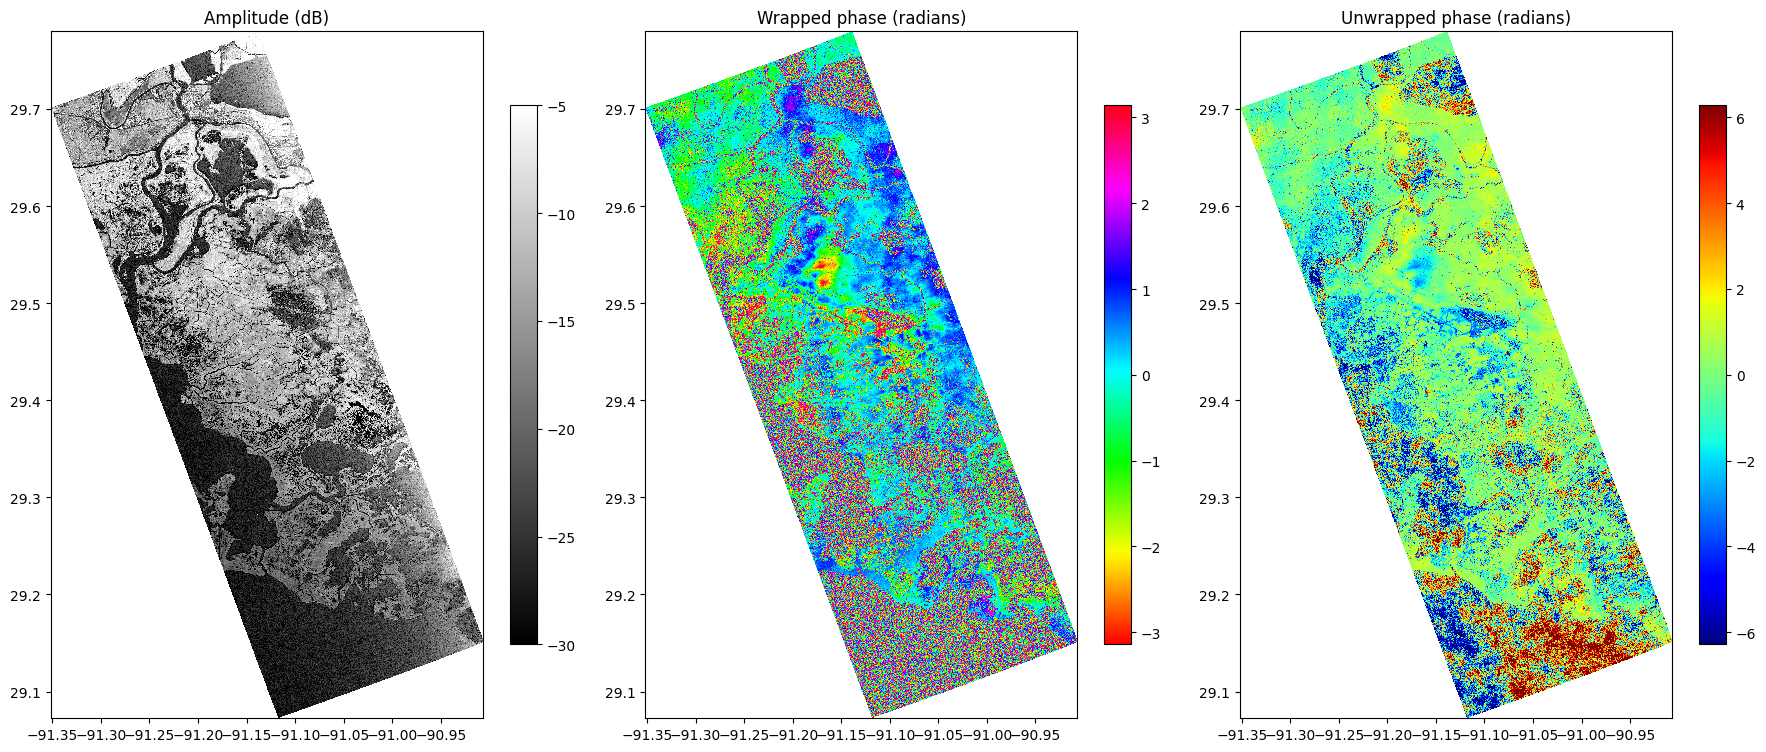

In [22]:
amp_ov, w_int_ov, unw_int_ov = overview(geo_amp), overview(geo_w_int), overview(geo_unw_int)

fig, axes = plt.subplots(1, 3, figsize=(18, 8))
im = axes[0].imshow(10 * np.log10(amp_ov), extent=geo_extent, vmin=-30, vmax=-5,
                    interpolation='nearest', cmap='gray')
axes[0].set_title('Amplitude (dB)')
fig.colorbar(im, ax=axes[0], shrink=0.7)
im = axes[1].imshow(w_int_ov, extent=geo_extent, interpolation='nearest', cmap='hsv')
axes[1].set_title('Wrapped phase (radians)')
fig.colorbar(im, ax=axes[1], shrink=0.7)
im = axes[2].imshow(unw_int_ov, extent=geo_extent, vmin=-6.28, vmax=6.28,
                    interpolation='nearest', cmap='jet')
axes[2].set_title('Unwrapped phase (radians)')
fig.colorbar(im, ax=axes[2], shrink=0.7)
plt.tight_layout()
plt.show()

### Quality assurance mask

The L2 dataset includes a quality assurance (QA) mask for each interferogram. The masks were made by comparing the interferometric phase with NOAA NEXRAD weather radar images, and have three values:

| Value | Meaning |
|---|---|
| 0 | Clear sky |
| 1 | Weather feature present, with possible tropospheric phase delay |
| 2 | Tropospheric phase delay consistently detected in all interferograms of the acquisition |

Water vapor in the atmosphere delays the radar signal, which adds a phase change that is not caused by the surface. We plot the QA mask next to the unwrapped phase, within the swath.

{0: '44%', 1: '56%'}


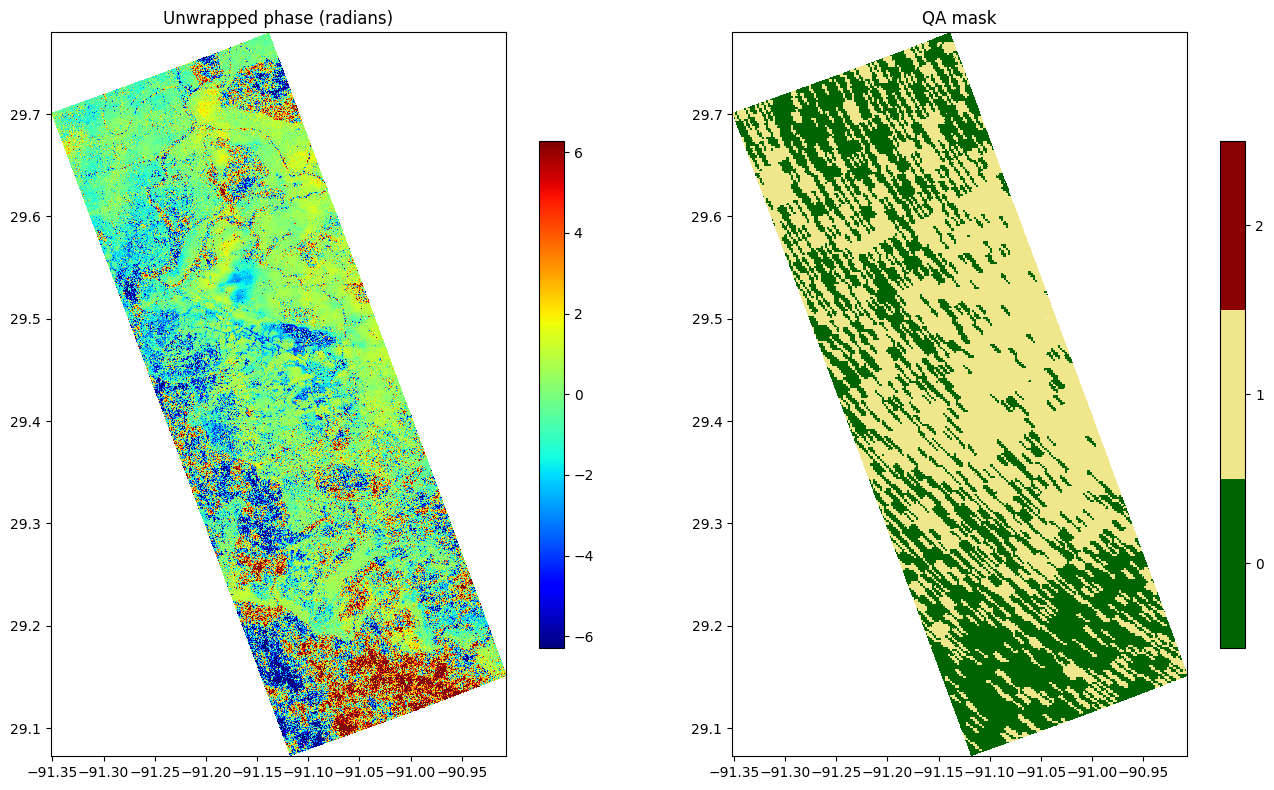

In [23]:
qa_ov = overview(geo_qa)
 # keep the mask within the swath
qa_ov = np.where(np.isfinite(coh_ov), qa_ov, np.nan) 
values, counts = np.unique(qa_ov[np.isfinite(qa_ov)], return_counts=True)
print({int(v): f'{100 * c / counts.sum():.0f}%' for v, c in zip(values, counts)})

fig, axes = plt.subplots(1, 2, figsize=(14, 8))
im = axes[0].imshow(unw_int_ov, extent=geo_extent, vmin=-6.28, vmax=6.28,
                    interpolation='nearest', cmap='jet')
axes[0].set_title('Unwrapped phase (radians)')
fig.colorbar(im, ax=axes[0], shrink=0.7)
qa_cmap = plt.matplotlib.colors.ListedColormap(['darkgreen', 'khaki', 'darkred'])
im = axes[1].imshow(qa_ov, extent=geo_extent, vmin=-0.5, vmax=2.5,
                    interpolation='nearest', cmap=qa_cmap)
axes[1].set_title('QA mask')
fig.colorbar(im, ax=axes[1], ticks=[0, 1, 2], shrink=0.7)
plt.tight_layout()
plt.show()

In this interferogram, many pixels are flagged as possibly affected by tropospheric delay (value 1). No area is flagged as consistently affected (value 2). To be conservative, we can keep only the pixels where `geo_qa == 0`.

### Mask the phase

As for L1B, we mask out pixels with a coherence below 0.5.

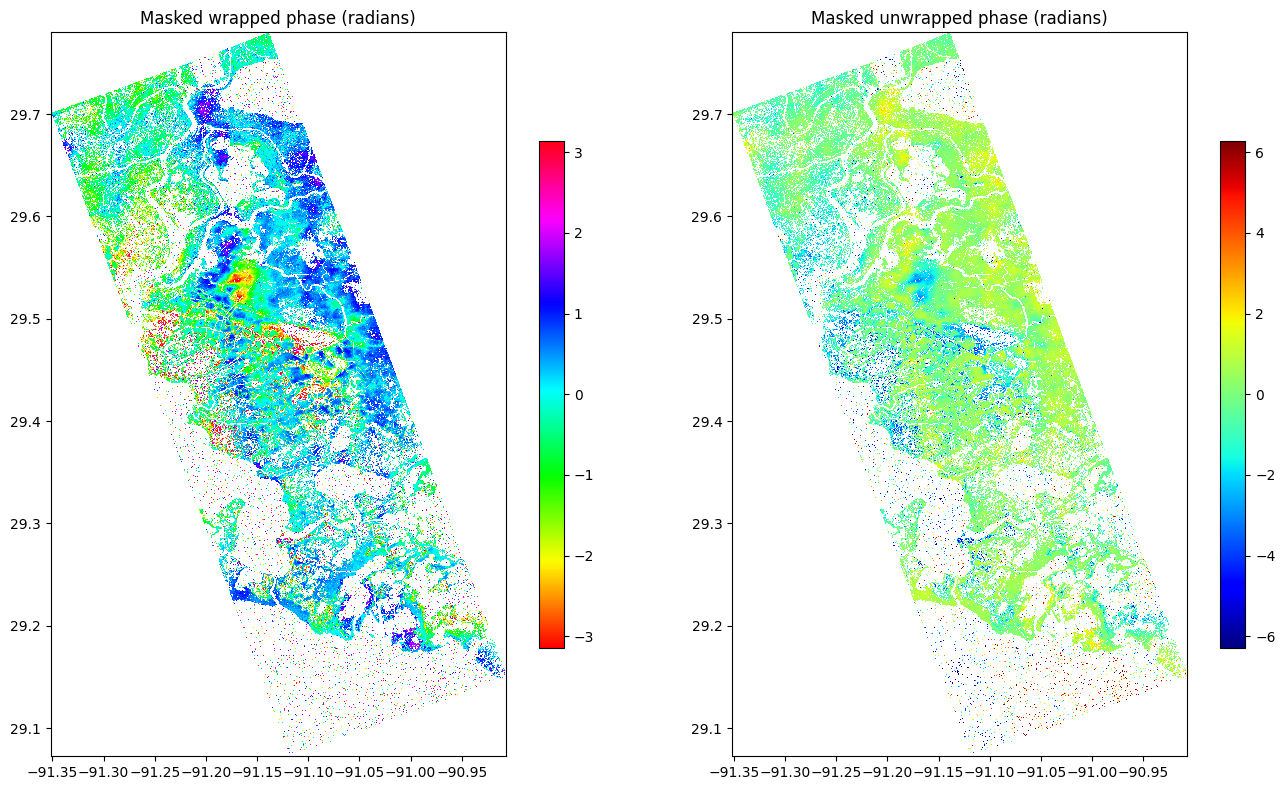

In [24]:
coh_msk_ov = coh_ov >= 0.5
fig, axes = plt.subplots(1, 2, figsize=(14, 8))
im = axes[0].imshow(np.where(coh_msk_ov, w_int_ov, np.nan), extent=geo_extent,
                    interpolation='nearest', cmap='hsv')
axes[0].set_title('Masked wrapped phase (radians)')
fig.colorbar(im, ax=axes[0], shrink=0.7)
im = axes[1].imshow(np.where(coh_msk_ov, unw_int_ov, np.nan), extent=geo_extent,
                    vmin=-6.28, vmax=6.28, interpolation='nearest', cmap='jet')
axes[1].set_title('Masked unwrapped phase (radians)')
fig.colorbar(im, ax=axes[1], shrink=0.7)
plt.tight_layout()
plt.show()

### Phase profile

With georeferenced data, we can define a profile by its coordinates. We extract a north-south profile. With `rioxarray`, we select the pixels by coordinates, and only the pixels of the profile are read from the file at full resolution.

In [25]:
lon, lat_start, lat_end = -91.12, 29.3, 29.2

def profile(da):
    # full-resolution values of a dataArray along the profile
    return da.sel(x=lon, method='nearest').sel(y=slice(lat_start, lat_end)).load()

pf_coh = profile(geo_coh)
pf_w_int = profile(geo_w_int).where(pf_coh >= 0.5)
pf_unw_int = profile(geo_unw_int).where(pf_coh >= 0.5)
print(f'Pixels along the profile: {pf_coh.size}, with coherence ≥ 0.5: {int((pf_coh >= 0.5).sum())}')

Pixels along the profile: 1800, with coherence ≥ 0.5: 840


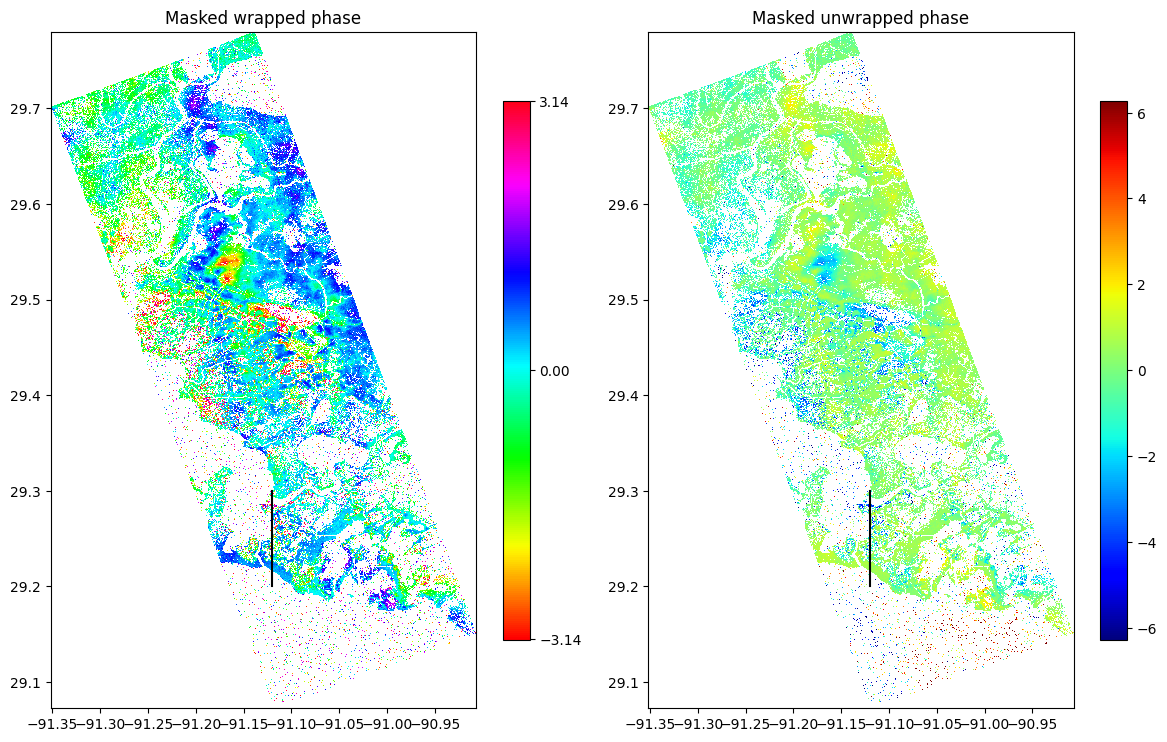

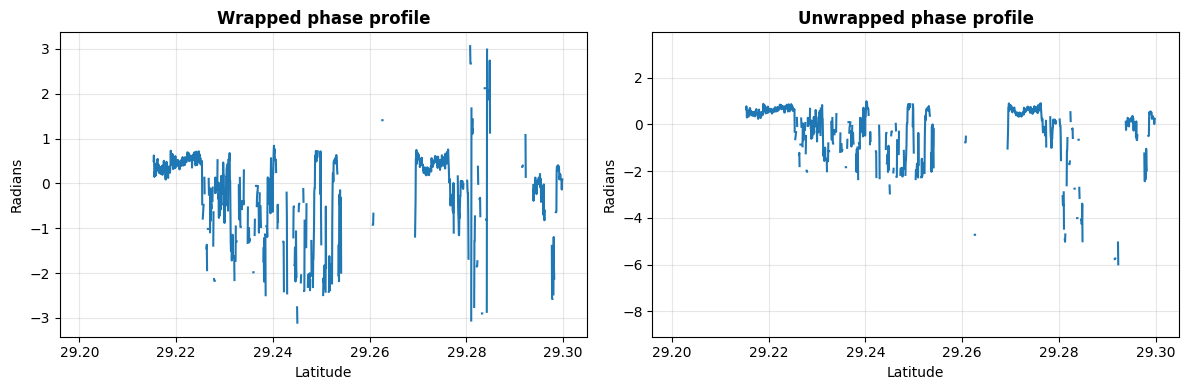

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(12, 8))
im = axes[0].imshow(np.where(coh_msk_ov, w_int_ov, np.nan), extent=geo_extent,
                    interpolation='nearest', cmap='hsv')
axes[0].set_title('Masked wrapped phase')
fig.colorbar(im, ax=axes[0], ticks=[-3.14, 0, 3.14], shrink=0.7)
im = axes[1].imshow(np.where(coh_msk_ov, unw_int_ov, np.nan), extent=geo_extent,
                    vmin=-6.28, vmax=6.28, interpolation='nearest', cmap='jet')
axes[1].set_title('Masked unwrapped phase')
fig.colorbar(im, ax=axes[1], shrink=0.7)
for ax in axes:
    ax.plot([lon, lon], [lat_start, lat_end], '-k')
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
pf_w_int.plot(ax=axes[0])
axes[0].set_title('Wrapped phase profile', fontweight='bold')
pf_unw_int.plot(ax=axes[1])
axes[1].set_title('Unwrapped phase profile', fontweight='bold')
for ax in axes:
    ax.set_xlabel('Latitude')
    ax.set_ylabel('Radians')
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Along the profile, the phase is masked where the coherence is below 0.5, which leaves segments of wetland pixels separated by gaps, for example at channels and open water. More information on InSAR phase unwrapping error correction in wetlands, refer to [this pubication](https://doi.org/10.1109/TGRS.2021.3108751).